# **PRAKTIKUM PEMBELAJARAN MESIN**

**Nama**  : Mufliha Hafsyah Shahieza <br>
**NIM**   : 244107020147 <br>
**Kelas** : TI-3G

---

# **JS04 - Klasterisasi**
# **Tugas Praktikum**<hr>

## **1. Tugas K-Means**


### **Langkah 1 — Persiapan Data**

Mengimpor library yang dipakai (`pandas`, `numpy`, `matplotlib`, `KMeans`, `StandardScaler`, dll.).

In [1]:
# Persiapan data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

### **Langkah 2 — Memuat Dataset**

Membaca `Mall_Customers.csv` dan menampilkan 5 baris teratas.

In [2]:
df = pd.read_csv('Mall_Customers.csv')

df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### **Langkah 3 — Seleksi Fitur**

Mengambil kolom fitur yang dipakai untuk clustering (kolom ke-2 sampai ke-4).

In [3]:
# Seleksi Fitur

X = df.iloc[:, 2:5]
y = df.iloc[:, -1]

X.head()

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


### **Langkah 4 — Standardisasi Fitur**

`StandardScaler` menyetarakan skala tiap fitur agar tidak ada yang mendominasi jarak.

In [4]:
std = StandardScaler()
X_scaled = std.fit_transform(X)
pd.DataFrame(X_scaled, columns=X.columns)

,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980
...,...,...,...
195,-0.276302,2.268791,1.118061
196,0.441365,2.497807,-0.861839
197,-0.491602,2.497807,0.923953
198,-0.491602,2.917671,-1.250054


### **Langkah 5 — Metode Elbow (SSE per k)**

Menghitung SSE untuk `k` = 1..9 guna menentukan jumlah cluster terbaik.

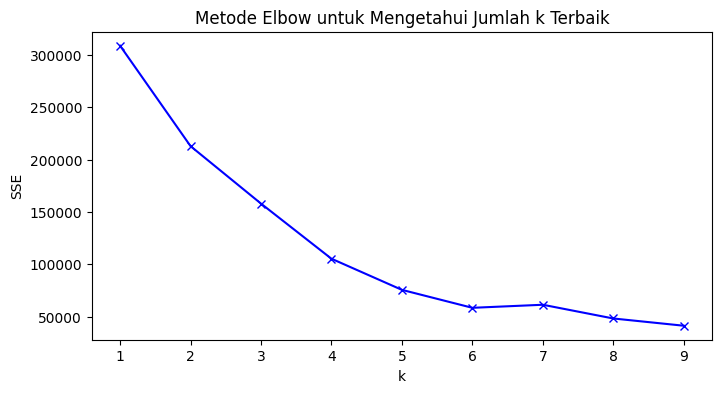

In [5]:
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
 kmeanModel = KMeans(n_clusters=k)
 kmeanModel.fit(X)
 sse.append(kmeanModel.inertia_)


# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

### **Langkah 6 — Plot Sebaran Data**

Melihat sebaran dua fitur terpilih sebelum di-cluster.

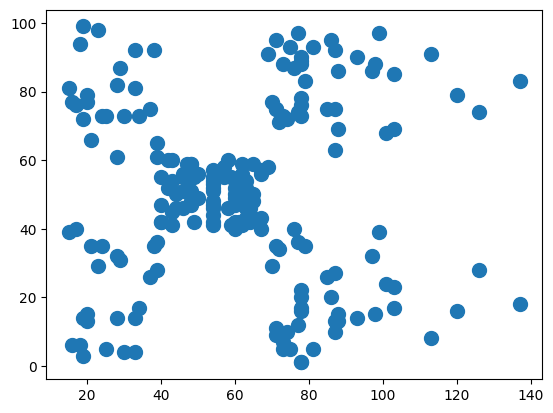

In [6]:
plt.scatter(X.iloc[:, 1], X.iloc[:, 2], s = 100)

### **Langkah 7 — Uji Beberapa Nilai k (4, 5, 6)**

Membandingkan hasil clustering pada tiga kandidat `k` hasil pembacaan grafik elbow.

/tmp/ipykernel_1256/1771374131.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


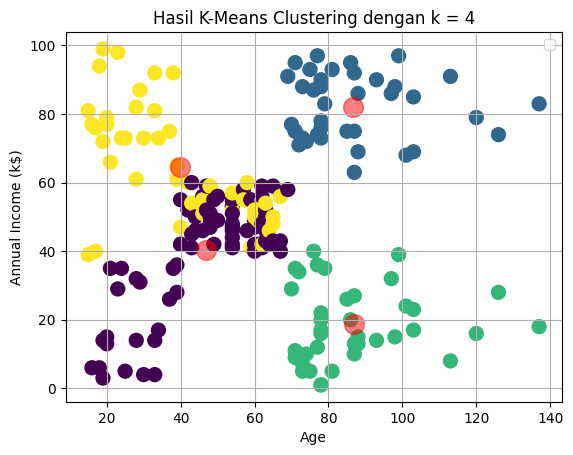

/tmp/ipykernel_1256/1771374131.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


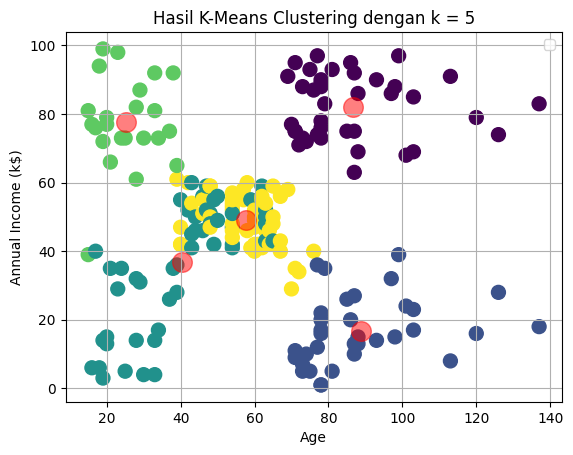

/tmp/ipykernel_1256/1771374131.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


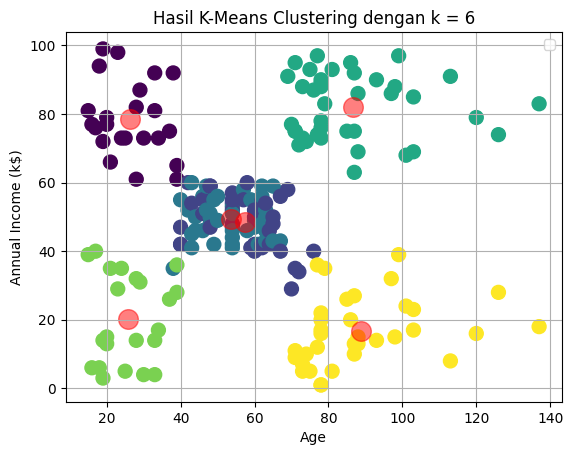

In [7]:
K_terbaik = [4, 5, 6]

for k in K_terbaik:
    cl_kmeans = KMeans(n_clusters=k)
    # Fit dan predict model
    y_kmeans = cl_kmeans.fit_predict(X)
    plt.scatter(X.iloc[:, 1], X.iloc[:, 2], s = 100, c=y_kmeans)

    centers = cl_kmeans.cluster_centers_
    plt.scatter(centers[:, 1], centers[:, 2], c='red', s=200, alpha=0.5)

    plt.title(f"Hasil K-Means Clustering dengan k = {k}")
    plt.xlabel(X.columns[0])
    plt.ylabel(X.columns[1])
    plt.legend()
    plt.grid(True)
    plt.show()


## **2. Tugas DBSCAN**

### **Langkah 8 — Membuat Dataset Non-Linear (Tugas 2)**

`make_moons` 1000 titik + standardisasi — data yang tidak bisa dipisahkan secara linear.

In [8]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

X, labels_true = make_moons(
    n_samples=1000, random_state=0, noise=0.05
)

X = StandardScaler().fit_transform(X)

### **Langkah 9 — K-Means pada Data Non-Linear**

Menunjukkan K-Means gagal memisahkan dua bulan sabit.

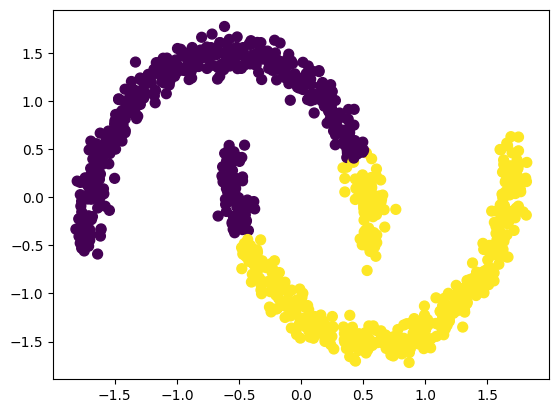

In [9]:
labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels,s=50, cmap='viridis');

### **Langkah 10 — DBSCAN pada Data Non-Linear**

`eps=0.2`, `min_samples=5` — pendekatan berbasis kepadatan menangani bentuk non-linear.

In [10]:
import numpy as np

from sklearn import metrics
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.2, min_samples=5).fit(X)
labels = db.labels_

# Number of clusters in labels, ignoring noise if present.
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 2
Estimated number of noise points: 0


### **Langkah 11 — Evaluasi Metrik**

Homogeneity, completeness, V-measure, ARI, dan AMI sebagai pembanding kualitas cluster.

In [11]:
from sklearn.metrics import homogeneity_score, completeness_score, v_measure_score
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score, silhouette_score

print(f"Homogeneity: {homogeneity_score(labels_true, labels):.3f}")
print(f"Completeness: {completeness_score(labels_true, labels):.3f}")
print(f"V-measure: {v_measure_score(labels_true, labels):.3f}")
print(f"Adjusted Rand Index: {adjusted_rand_score(labels_true, labels):.3f}")
print(
    "Adjusted Mutual Information: "
    f"{adjusted_mutual_info_score(labels_true, labels):.3f}"
)
print(f"Silhouette Coefficient: {silhouette_score(X, labels):.3f}")

Homogeneity: 1.000
Completeness: 1.000
V-measure: 1.000
Adjusted Rand Index: 1.000
Adjusted Mutual Information: 1.000
Silhouette Coefficient: 0.392


### **Langkah 12 — Visualisasi Hasil DBSCAN**

Menggambar cluster, core samples, dan noise.

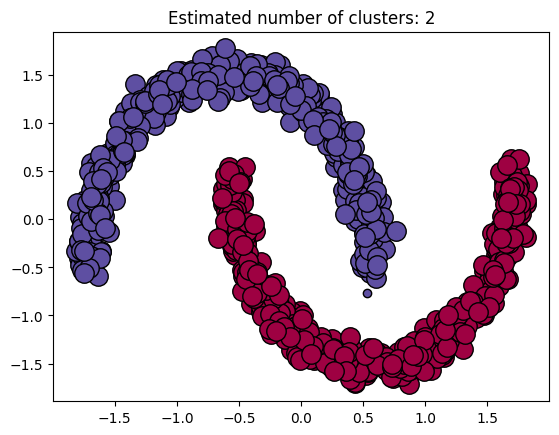

In [12]:
unique_labels = set(labels)
core_samples_mask = np.zeros_like(labels, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True

colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
for k, col in zip(unique_labels, colors):
    if k == -1:
        # Hitam digunakan untuk noise.
        col = [0, 0, 0, 1]

    class_member_mask = labels == k

    xy = X[class_member_mask & core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=14,
    )

    xy = X[class_member_mask & ~core_samples_mask]
    plt.plot(
        xy[:, 0],
        xy[:, 1],
        "o",
        markerfacecolor=tuple(col),
        markeredgecolor="k",
        markersize=6,
    )

plt.title(f"Estimated number of clusters: {n_clusters_}")
plt.show()

### **Langkah 13 — Eksperimen Grid `eps` × `min_samples`**

Menguji kombinasi nilai `eps` (0.05–0.5) dan `min_samples` (3, 10, 20) untuk melihat sensitivitas kedua parameter itu.

In [13]:
eps_values = [0.05, 0.1, 0.3, 0.5]
min_samples_values = [3, 10, 20]

for e in eps_values:
    for ms in min_samples_values:
        dbs_exp = DBSCAN(eps=e, min_samples=ms)
        lbls = dbs_exp.fit_predict(X)
        n_cl = len(set(lbls)) - (1 if -1 in lbls else 0)
        n_ns = list(lbls).count(-1)

        # Evaluasi ringkas
        ari_exp = metrics.adjusted_rand_score(labels_true, lbls)
        print(f"eps={e}, min_samples={ms} --> Klaster: {n_cl}, Noise: {n_ns}, ARI: {ari_exp:.4f}")

eps=0.05, min_samples=3 --> Klaster: 67, Noise: 197, ARI: 0.0330
eps=0.05, min_samples=10 --> Klaster: 0, Noise: 1000, ARI: 0.0000
eps=0.05, min_samples=20 --> Klaster: 0, Noise: 1000, ARI: 0.0000
eps=0.1, min_samples=3 --> Klaster: 3, Noise: 18, ARI: 0.8543
eps=0.1, min_samples=10 --> Klaster: 9, Noise: 63, ARI: 0.4351
eps=0.1, min_samples=20 --> Klaster: 6, Noise: 844, ARI: 0.0104
eps=0.3, min_samples=3 --> Klaster: 2, Noise: 0, ARI: 1.0000
eps=0.3, min_samples=10 --> Klaster: 2, Noise: 0, ARI: 1.0000
eps=0.3, min_samples=20 --> Klaster: 2, Noise: 0, ARI: 1.0000
eps=0.5, min_samples=3 --> Klaster: 1, Noise: 0, ARI: 0.0000
eps=0.5, min_samples=10 --> Klaster: 1, Noise: 0, ARI: 0.0000
eps=0.5, min_samples=20 --> Klaster: 2, Noise: 0, ARI: 0.9960
